# 1. Effective Hamiltonian and energy spectrum

**Author:** Aditya Banerjee  
**Thesis:** *Linear Anyon Model with Rydberg Atoms*, Universitat de Barcelona, 2026

The thesis extends the effective two-site operator to a chain. Since each exchange preserves total occupation, the spectrum can be calculated one particle-number sector at a time.

**Thesis source:** Sections 3.6–3.7, Eqs. (41)–(47), Figure 2. Descriptions below are adapted from these sections;
equation numbers refer to the thesis. **Code source:** [`heff2_E_vs_N.py`](../scripts/heff2_E_vs_N.py), [`heff2_E_vs_N_thesis.py`](../scripts/heff2_E_vs_N_thesis.py).

**Steps:** libraries → parameters → bond energies → exchange → number sectors → spectrum → interpretation.

Run the numbered sections from top to bottom. Longer derivations and implementation
comparisons are at the end. These are theoretical calculations, not experimental data.

## 1. Import libraries and locate the saved data

In [1]:
%matplotlib inline
from pathlib import Path
from itertools import product
import numpy as np
from scipy.special import jv
import matplotlib.pyplot as plt
from IPython.display import display

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
# Run from the repository root or from notebooks/.
here = Path.cwd().resolve()
ROOT = next(p for p in [here, *here.parents] if (p / "scripts").is_dir() and (p / "data").is_dir())
DATA = ROOT / "data"
SAVE_FIGURES = False
STYLE = {"font.size": 11}


def show_figure(fig, name):
    if SAVE_FIGURES:
        destination = ROOT / "notebook_outputs"
        destination.mkdir(exist_ok=True)
        fig.savefig(destination / f"{name}.png", dpi=160)
    display(fig)
    plt.close(fig)

## 2. Set the thesis parameters

Use the source ten-site open chain. Only a small sector is diagonalized here; the complete spectrum is loaded from its saved file.

**Symbols used in the code**

| Thesis symbol | Code name | Meaning |
|---|---|---|
| $C_{ab}$ | `C00`, `C01`, … | Interaction-shift parameters |
| $\Omega_\alpha,\Omega_\beta$ | `Om_a`, `Om_b` | Laser-coupling amplitudes |
| $\omega'$ | `wp` or `WP` | Drive rate |
| $A$ | `A` | Detuning-modulation amplitude |
| $\kappa=A/\omega'$ | `kappa` or `kap` | Dimensionless modulation index |
| $L$ | `L` | Number of sites |
| $N$ | `N` | Total occupation quanta |

The bare pair energies are $2C_{00},C_{01},2C_{11},C_{02},C_{12},2C_{22}$.
The $C$, $\Omega$, $\omega'$, and $A$ values use one **native numerical rate unit**.
$J_\ell(\kappa)$ is the Bessel function of integer order $\ell$.

Evolution uses $K=H/(\hbar\omega_{\rm ref})$ and $\tau=\omega_{\rm ref}t$,
with $[\hbar\omega_{\rm ref}]={\rm J}$ and $[\tau]=1$; the reference is one
native rate unit. This preserves the source numbers without claiming a calibrated
microsecond axis while the cycles-versus-radians convention remains unresolved.

In [3]:
C00, C01, C11 = 0.0, 20.0, 15.0
C02, C12, C22 = 2 * C11, 45.0, 55.0
Om_a, Om_b = 1.0, 1.0
WP, A, N_RES = 40.0, 48.0, 1
COMPENSATE_11BLOCK = True
LMAX = 60
ells = np.arange(-LMAX, LMAX + 1)
d = 3

L, usePBC, THETA = 10, False, 0.0

## 3. Calculate the sideband sums

Thesis Eq. (41) sums the virtual sidebands.
We write $S(X)/\Omega_\beta^2$ as `ss(X)`:
$$S(X)/\Omega_\beta^2=\sum_\ell\frac{J_\ell(\kappa)^2}{X+\widetilde\nu+\ell\omega'}.$$
Each denominator is a rate, so the sum has inverse-rate units. `LMAX` sets the finite cutoff.

In [4]:
kap = A / WP
nu = 2 * C11 - C02 - N_RES * WP
Jl = jv(ells, kap)


def ss(dc):
    den = dc + nu + ells * WP
    if np.any(np.abs(den) < 1e-9):
        raise ZeroDivisionError("resonant Stark denominator at WP=%g" % WP)
    return float(np.sum(Jl**2 / den))

## 4. Build the diagonal energies

Thesis Eq. (42) gives the AC Stark shifts.
For example, $E_{00}=-2\Omega_\alpha^2/(C_{01}-2C_{00})$.
The following cell evaluates all nine entries. **Source assumption:** the optional
$E_{11}\leftarrow E_{20}$ compensation is an imposed shift, not a self-consistent retuning.

In [5]:
E = {}
E["00"] = -2 * Om_a**2 / (C01 - 2 * C00)
E["01"] = Om_a**2 / (C01 - 2 * C00) - Om_a**2 / (2 * C11 - C01) - Om_b**2 * ss(C02 - C01)
E["02"] = Om_b**2 * ss(C02 - C01) - Om_a**2 / (C12 - C02)
E["10"] = E["01"]
E["11"] = 2 * Om_a**2 / (2 * C11 - C01) - 2 * Om_b**2 * ss(C12 - 2 * C11)
E["12"] = Om_a**2 / (C12 - C02) + Om_b**2 * ss(C12 - 2 * C11) - Om_b**2 * ss(2 * C22 - C12)
E["20"] = E["02"]
E["21"] = E["12"]
E["22"] = 2 * Om_b**2 * ss(2 * C22 - C12)
if COMPENSATE_11BLOCK:
    E["11"] += E["20"] - E["11"]

## 5. Calculate the four exchange amplitudes

Thesis Eq. (43) connects
$01\leftrightarrow10$, $11\leftrightarrow20$, $02\leftrightarrow11$, and $12\leftrightarrow21$.
For example,
$$g_1=\Omega_\alpha^2\left[\frac1{C_{01}-2C_{00}}-\frac1{2C_{11}-C_{01}}\right].$$
The signed rates are kept; the reverse matrix elements are their complex conjugates.

In [6]:
g1 = Om_a**2 * (1.0 / (C01 - 2 * C00) - 1.0 / (2 * C11 - C01))
pref = Om_a * Om_b * (1.0 / (2 * C11 - C01) - 1.0 / (C12 - C02))
g2 = pref * jv(N_RES, kap)
g3 = pref * jv(N_RES, kap)
Sig = 1.0 / (C12 - 2 * C11 + nu + ells * WP) - 1.0 / (2 * C22 - C12 + nu + ells * WP)
g4 = Om_b**2 * float(np.sum(Jl * jv(ells, kap) * Sig))
Eb = np.array([[E["%d%d" % (a, b)] for b in range(d)] for a in range(d)])
gs = (g1, g2, g3, g4)
print("Signed exchange rates:", np.array(gs))

Signed exchange rates: [-0.05     0.01661  0.01661 -0.01012]


## 6. Select a particle-number sector

From thesis Eq. (46),
$$\widehat N=\sum_j\widehat n_j,\qquad [H,\widehat N]=0.$$
$L$ counts sites and $N$ counts occupation quanta. Each site has $n_j=0,1,2$;
the basis is orthonormal and the chain has open ends. The original code uses
base-three indices to locate the exchanged configurations.

In [7]:
configs = np.array(list(product(range(d), repeat=L)), dtype=np.int8)
Nvec = configs.sum(axis=1).astype(int)
PW = np.array([d ** (L - 1 - j) for j in range(L)], dtype=np.int64)
DIMFULL = d**L
BONDS = [(j, j + 1) for j in range(L - 1)]
if usePBC:
    BONDS.append((L - 1, 0))


def phases_of(theta):
    a, b = 0.0, theta  # alpha = 0, beta = theta
    return -a, b - 2 * a, a - 2 * b, -b


TH = phases_of(THETA)
REAL_PATH = all(abs(np.sin(t)) < 1e-14 for t in TH)

In [8]:
def sector_levels(N, Eb, gs):
    """All eigenvalues of H_eff^(2) in the sector of particle number N."""
    rows = np.where(Nvec == N)[0]
    dim = len(rows)
    pos = np.full(DIMFULL, -1, dtype=np.int64)
    pos[rows] = np.arange(dim)
    cfg = configs[rows]
    g1, g2, g3, g4 = gs
    dtype = np.float64 if REAL_PATH else np.complex128
    H = np.zeros((dim, dim), dtype=dtype)
    diag = np.zeros(dim)
    for jL, jR in BONDS:
        diag += Eb[cfg[:, jL], cfg[:, jR]]
    H[np.arange(dim), np.arange(dim)] = diag
    for jL, jR in BONDS:
        for (a, b), (a2, b2), g, t in [
            ((0, 1), (1, 0), g1, TH[0]),
            ((1, 1), (2, 0), g2, TH[1]),
            ((0, 2), (1, 1), g3, TH[2]),
            ((1, 2), (2, 1), g4, TH[3]),
        ]:
            if g == 0.0:
                continue
            amp = g * np.cos(t) if REAL_PATH else g * np.exp(1j * t)
            sel = np.where((cfg[:, jL] == a) & (cfg[:, jR] == b))[0]
            if sel.size == 0:
                continue
            tgt = pos[rows[sel] + (a2 - a) * PW[jL] + (b2 - b) * PW[jR]]
            H[tgt, sel] += amp
            H[sel, tgt] += np.conj(amp)
    tr = float(np.trace(H).real)
    return np.linalg.eigvalsh(H), tr

In [9]:
N_DEMO = 2
sector_energy, sector_trace = sector_levels(N_DEMO, Eb, gs)
print("N =", N_DEMO, "dimension =", len(sector_energy))
print("First five energies:", sector_energy[:5])

N = 2 dimension = 55
First five energies: [-0.919334 -0.908133 -0.902681 -0.891066 -0.885725]


## 7. Load the complete saved spectrum

The saved Figure 2 data contain all $3^{10}=59049$ levels. Loading them does not repeat the full diagonalization.

In [10]:
with np.load(DATA / "heff2_E_vs_N_L10.npz", allow_pickle=False) as saved:
    cached_L = int(saved["L"])
    energy, number = saved["E"].copy(), saved["NLAB"].copy()
Ns = np.arange(2 * cached_L + 1)
E0 = np.array([energy[number == N].min() for N in Ns])
Emax = np.array([energy[number == N].max() for N in Ns])
print("Loaded", len(energy), "levels for L =", cached_L)

Loaded 59049 levels for L = 10


## 8. Plot the extensive and intensive spectra

Figure 2 compares $E$ versus $N$
with $E/L$ versus $\bar n=N/L$ [Eq. (47)]. Dividing both axes by $L$ gives
the energy per site and average occupation. Each column contains one number sector.

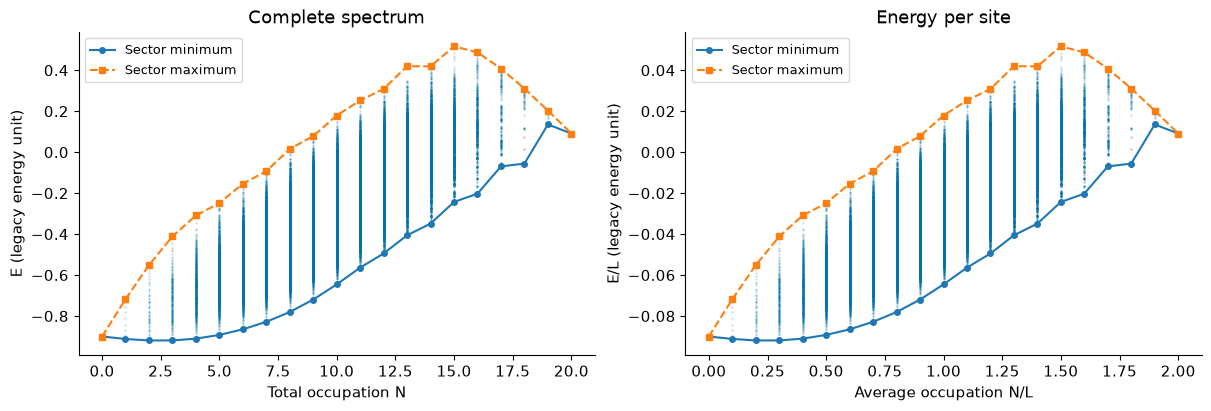

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for ax, scale in zip(axes, [1, cached_L]):
    ax.plot(number / scale, energy / scale, ".", ms=1, alpha=0.25, color="#0072B2")
    ax.plot(Ns / scale, E0 / scale, "o-", ms=4, label="Sector minimum")
    ax.plot(Ns / scale, Emax / scale, "s--", ms=4, label="Sector maximum")
    ax.legend(fontsize=9)
axes[0].set(xlabel="Total occupation N", ylabel="E (legacy energy unit)", title="Complete spectrum")
axes[1].set(
    xlabel="Average occupation N/L", ylabel="E/L (legacy energy unit)", title="Energy per site"
)
show_figure(fig, "01_spectrum")

## 9. Read the result and check it

The lowest energies can belong to different number sectors. A global level spacing therefore need not be an excitation at fixed filling.

In [12]:
ground = np.argmin(energy)
print("Global ground-state sector:", int(number[ground]))
print("Ground-state energy:", energy[ground])
print("Low-filling minima:", list(zip(Ns[:5], E0[:5])))
np.testing.assert_allclose(sector_energy, np.sort(energy[number == N_DEMO]), atol=2e-12)
assert sum(np.count_nonzero(number == N) for N in Ns) == 3**cached_L
print("Saved-sector comparison and total dimension: PASS")

Global ground-state sector: 2
Ground-state energy: -0.9193344948131369
Low-filling minima: [(np.int64(0), np.float64(-0.8999999999999999)), (np.int64(1), np.float64(-0.9119760858605935)), (np.int64(2), np.float64(-0.9193344948131369)), (np.int64(3), np.float64(-0.9192076910146696)), (np.int64(4), np.float64(-0.910373805288799))]
Saved-sector comparison and total dimension: PASS


## Appendix — detailed derivations and verification

The main calculation is complete. This appendix retains the symbolic steps, conventions, limiting cases, and source comparisons for closer study.

### Conventions, dimensions, and evidence status

**Theoretical model:** each site has the orthonormal occupation basis
$|0\rangle,|1\rangle,|2\rangle$. The tensor-product basis is lexicographic,
with the leftmost site the most significant index. Occupations above two are
excluded. State vectors have norm one; probabilities and occupation numbers
are dimensionless. Chains use open boundaries unless explicitly stated.
This is a nonrelativistic finite-dimensional calculation; no spacetime metric
signature is used. Finite sums replace spatial integration, and no continuum
boundary conditions are assumed.

Start with physical energy $H$ and positive reference angular frequency
$\omega_{\rm ref}$. Define
$$K=\frac{H}{\hbar\omega_{\rm ref}},\qquad
  \tau=\omega_{\rm ref}t,\qquad \hbar=\frac{h}{2\pi}.$$
Since $[H]={\rm J}$ and $[\hbar\omega_{\rm ref}]={\rm J\,s}\,{\rm s}^{-1}
={\rm J}$, $K$ is dimensionless. Likewise $[\tau]={\rm s}^{-1}{\rm s}=1$.
Schrödinger evolution becomes
$$i\hbar\,\omega_{\rm ref}\frac{d\psi}{d\tau}
   =\hbar\omega_{\rm ref}K\psi,
  \qquad i\frac{d\psi}{d\tau}=K\psi.$$

**Unresolved source convention:** archived scripts label numerical rates as
MHz while using the numerical matrix in $\exp(-iEt)$; a header also equates MHz with rad/us.
Appendix B of the thesis writes $\omega'/2\pi$ in MHz. If a matrix is supplied
as $H/h$ in cycles per unit time, its propagator is $\exp[-i2\pi(H/h)t]$;
if supplied as $H/\hbar$, it is $\exp[-i(H/\hbar)t]$. Dimensional analysis
cannot distinguish these two conventions. The notebooks therefore preserve
native numerical values and use $\tau$, without claiming a calibrated
microsecond axis. Any physical conversion requires a declared convention.
For the effective-model numerical cells, the reference is one native rate
unit: a rate divided by that reference has the same numerical value.
Thus the arrays used in the propagator are dimensionless $K$, even when
the source-formula coefficients are described below as native rates.

**Source-backed numerical facts** refer to the archived files and checks
shown here. They are not experimental observations. **Physical reachability**
and **proposed extensions** are labelled separately. See
[scientific notes](../SCIENTIFIC_NOTES.md) for unresolved interpretations.

### 1.1 From a bond to a chain

On one bond, $|ab\rangle$ means $a$ quanta on the left and $b$ on the right.
Write the numerical rate matrix as $K_{\rm bond}=D+T+T^\dagger$, where
$$D=\sum_{a,b=0}^{2}\epsilon_{ab}|ab\rangle\langle ab|,$$
$$T=g_1e^{i\vartheta_1}|10\rangle\langle01|
   +g_2e^{i\vartheta_2}|20\rangle\langle11|
   +g_3e^{i\vartheta_3}|11\rangle\langle02|
   +g_4e^{i\vartheta_4}|21\rangle\langle12|.$$
The real signed $g_i$ retain the source convention; $|g_i|$ are magnitudes.
The complex conjugate transpose supplies each reverse process once, so
$K_{\rm bond}^\dagger=K_{\rm bond}$. For an open chain,
$$K=\sum_{j=0}^{L-2}K_{{\rm bond},j,j+1}.$$
Both the diagonal and the hopping are bond terms. Replacing these diagonal
terms by a conventional on-site Hubbard interaction would define a different
Hamiltonian; we do not do that here.

### 1.2 Second-order rates and the perturbative assumption

Here $C_{ab}$ are the source interaction-shift parameters. Their
normalization is $E^{(0)}_{00}=2C_{00}$, $E^{(0)}_{01}=C_{01}$,
$E^{(0)}_{11}=2C_{11}$, $E^{(0)}_{02}=C_{02}$,
$E^{(0)}_{12}=C_{12}$, and $E^{(0)}_{22}=2C_{22}$;
exchanging the two sites does not change these bare energies.
$\Omega_a,\Omega_b$ are real laser-coupling amplitudes in the source
normalization, $A$ is the detuning-modulation amplitude, and $\omega'$ is
the drive rate. All use one declared native rate unit.
$J_\ell$ is the Bessel function of the first kind of integer order $\ell$;
$\ell_{\max}$ is the numerical sideband cutoff. The argument $d$ in $S(d)$
is a bare transition-rate difference, and $\widetilde\nu$ is the common
detuning offset in the locked-resonance family. The four
$\vartheta_i$ are dimensionless bond phases; $L$ is the number of sites.

A representative eliminated-state contribution has rate $\Omega^2/\Delta$.
Its dimension is $({\rm s}^{-1})^2/({\rm s}^{-1})={\rm s}^{-1}$.
Dividing by $\omega_{\rm ref}$ gives a dimensionless entry of $K$.
The approximation requires $|\Omega/\Delta|\ll1$ for the contributing
denominators. A nonzero denominator alone is not enough.

A sinusoidal drive gives dimensionless $\kappa=A/\omega'$ and Bessel weights:
$$S(d)=\sum_{\ell=-\ell_{\max}}^{\ell_{\max}}
  \frac{J_\ell(\kappa)^2}{d+\widetilde\nu+\ell\omega'}.$$
$S$ has inverse-rate dimensions. The locked family uses
$\widetilde\nu=2C_{11}-C_{02}-m\omega'$ with integer resonance order $m$.
In native numerical units, define
$$D_1=\frac1{C_{01}-2C_{00}},\quad
  D_2=\frac1{2C_{11}-C_{01}},\quad D_3=\frac1{C_{12}-C_{02}},$$
$$g_1=\Omega_a^2(D_1-D_2),\qquad
  g_2=g_3=\Omega_a\Omega_b(D_2-D_3)J_m(\kappa),$$
$$g_4=\Omega_b^2\{S(C_{12}-2C_{11})-S(2C_{22}-C_{12})\}.$$
The notebook parameters retain the original numbers; $C$ and $\Omega$ here
are rate-equivalent quantities, not simultaneously SI energies.

The six distinct diagonal rates before compensation are
$$\epsilon_{00}=-2\Omega_a^2D_1,$$
$$\epsilon_{01}=\epsilon_{10}=\Omega_a^2(D_1-D_2)-\Omega_b^2S(C_{02}-C_{01}),$$
$$\epsilon_{02}=\epsilon_{20}=\Omega_b^2S(C_{02}-C_{01})-\Omega_a^2D_3,$$
$$\epsilon_{11}=2\Omega_a^2D_2-2\Omega_b^2S(C_{12}-2C_{11}),$$
$$\epsilon_{12}=\epsilon_{21}=\Omega_a^2D_3+
 \Omega_b^2\{S(C_{12}-2C_{11})-S(2C_{22}-C_{12})\},$$
$$\epsilon_{22}=2\Omega_b^2S(2C_{22}-C_{12}).$$
Every term is a squared rate times an inverse rate. Dividing these
$\epsilon$ and $g$ values by $\omega_{\rm ref}$ supplies the entries of $K$.

**Explicit modelling assumption:** the archived scripts replace
$\epsilon_{11}$ by $\epsilon_{20}$ to compensate a diagonal mismatch.
We expose that switch and report the imposed shift. This operation does not
recompute every denominator after a physical change of laser detuning.

### 1.3 Why fixed-particle-number sectors are exact

Define $\widehat N=\sum_j\widehat n_j$. A channel
$|ab\rangle\rightarrow|cd\rangle$ obeys
$$[\widehat N,|cd\rangle\langle ab|]
  =(c+d-a-b)|cd\rangle\langle ab|.$$
In the four channels the initial and final sums are respectively
$1\to1$, $2\to2$, $2\to2$, and $3\to3$, so every coefficient is zero.
Diagonal terms commute with $\widehat N$ as well. Adding the terms gives
$$[K,\widehat N]=0,\qquad K=\bigoplus_{N=0}^{2L}K_N.$$
Thus a fixed-$N$ calculation is exact **within this truncated Hamiltonian**.
Degenerate eigenvalues in different sectors need not have the same $N$;
diagonalizing each sector labels them unambiguously.

The number of configurations in sector $N$ is the coefficient of $z^N$ in
$(1+z+z^2)^L$. Adding all sector dimensions gives $(1+1+1)^L=3^L$.

### 1.5 Limiting and convergence checks

With all hopping rates zero, $K$ is diagonal and its eigenvalues are its
diagonal entries. With phases zero and real rates, $K$ is real symmetric.
Increasing the sideband cutoff should stabilize retained rates; this checks
the finite sum, not the validity of perturbation theory itself.

### Compare the notebook calculation with the validated reference

The following cell is an implementation check. The main calculation above contains its own code and does not require these reference imports.

In [13]:
import sys

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from anyon_thesis.models import effective_bond, effective_chain

reference_diagonal, reference_rates, _ = effective_bond()
np.testing.assert_allclose(Eb, reference_diagonal, atol=1e-13)
np.testing.assert_allclose(gs, reference_rates, atol=1e-13)
reference_H, _ = effective_chain(L, Eb, gs, total_number=N_DEMO)
np.testing.assert_allclose(sector_energy, np.linalg.eigvalsh(reference_H), atol=2e-12)
print("Visible source cells agree with the validated reference: PASS")

Visible source cells agree with the validated reference: PASS


### Sources and adaptations

- [Read the thesis](https://hdl.handle.net/2445/231684); thesis equation numbers are identified beside their use.
- Original calculation code: [`heff2_E_vs_N.py`](../scripts/heff2_E_vs_N.py), [`heff2_E_vs_N_thesis.py`](../scripts/heff2_E_vs_N_thesis.py), source commit `22959963191fcbc4d283ec4b272b506ad6dd979b`.
- [Scientific notes](../SCIENTIFIC_NOTES.md): frequency convention, imposed compensation, physical phase reachability, and finite-size interpretation.
- [Validation and adaptation record](VALIDATION.md).
- Notebook layout follows the short, numbered explanation–code–output pattern of the
  [AQI example](https://github.com/Charub17/global-air-pollution-aqi-ml/blob/main/Global_Air_Pollution_AQI_ML.ipynb).
  Its prose, data analysis, and numerical claims are not reused.

The code cells retain the source calculations. Notebook-specific adaptations are
labelled beside the relevant cell. No large archived job is launched implicitly.